#### Coherence(x와 y의 일관성 챠트)
 : 서로 다른 두 신호와 특정 주파수영역에서 얼마나 비슷한 패턴으로 연관되어 움직이는지를 0과 1사이의 값으로 나타낸 지표
- 수치해석(0~1)
    - 1에 가까움 : 해당 주파수에서 두 신호가 매우 강한 선형적 관계를 가짐
    - 0에 가까움 : 해당 주파수에서 두 신호는 아무 관계가 없다. 노이즈
- 활용
    - 음향 및 진동 분석: 원인 규명
    - 뇌파 분석
    - 제어 시스템

In [1]:
import matplotlib.pyplot as plt
import numpy as np

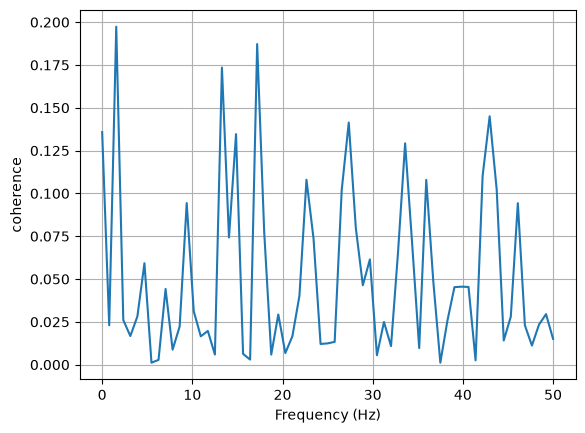

In [3]:
# 신호 데이터 생성
dt = 0.01
t = np.arange(0, 30, dt)
n1 = np.random.randn(len(t))
n2 = np.random.randn(len(t))

s1 = 1.5 * np.sin(2*np.pi*10*t) + n1
s2 = np.cos(np.pi * t) + n2

plt.cohere(s1, s2**2, NFFT=128, Fs=1.0 / dt)
plt.xlabel('Frequency (Hz)')
plt.ylabel('coherence');

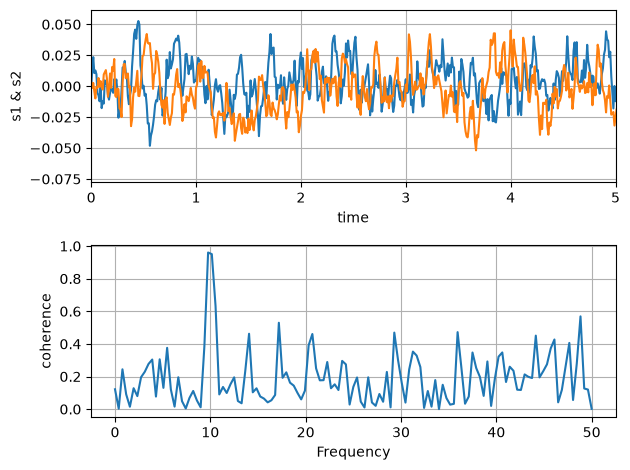

In [5]:
dt = 0.01
t = np.arange(0, 30, dt)
n1 = np.random.randn(len(t))
n2 = np.random.randn(len(t))
r = np.exp(-t/0.05)

c1 = np.convolve(n1, r, mode='same') * dt
c2 = np.convolve(n2, r, mode='same') * dt

s1 = 0.01 * np.sin(2 * np.pi * 10 * t) + c1
s2 = 0.01 * np.sin(2 * np.pi * 10 * t) + c2

plt.subplot(211)
plt.plot(t, s1, t, s2)
plt.xlim(0, 5)
plt.xlabel('time')
plt.ylabel('s1 & s2')
plt.grid(True)

plt.subplot(212)
plt.cohere(s1, s2, NFFT=256, Fs=1. / dt)
plt.ylabel('coherence')

plt.tight_layout()
